In [43]:
%pip install simpy matplotlib numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [44]:
import simpy
import random
import numpy as np
import matplotlib.pyplot as plt

# parametros del sistema
RANDOM_SEED = 42
LAMBDA = 1.8   # λ: tasa media de llegadas
MU = 2.0       # μ: tasa media de servicio
N_EVALUAR = 3  # n: numero de clientes para la probabilidad P_n
TIEMPO_SIMULACION = 1000 # tiempo en minutos

tiempos_espera = []      # tiempo en fila (Wq)
tiempos_sistema = []     # tiempo en sistema (Ws)
tamano_cola = []         # longitud de la fila (Lq)
tamano_sistema = []      # clientes en sistema (Ls)
tiempos_registro = []

In [45]:
# procesos con SimPy
def visitante(env, nombre, atraccion):
    tiempo_llegada = env.now
    
    with atraccion.request() as turno:
        yield turno  # espera en fila
        
        tiempo_inicio_servicio = env.now
        espera_fila = tiempo_inicio_servicio - tiempo_llegada
        tiempos_espera.append(espera_fila)
        
        # tiempo de servicio exponencial (1/μ)
        duracion_servicio = random.expovariate(MU)
        yield env.timeout(duracion_servicio)
        
        tiempo_salida = env.now
        tiempos_sistema.append(tiempo_salida - tiempo_llegada)

def generador_visitantes(env, atraccion):
    i = 0
    while True:
        # tiempo entre llegadas exponencial (1/λ)
        tiempo_entre_llegadas = random.expovariate(LAMBDA)
        yield env.timeout(tiempo_entre_llegadas)
        
        i += 1
        env.process(visitante(env, f'Cliente {i}', atraccion))

def monitor_sistema(env, atraccion):
    while True:
        en_cola = len(atraccion.queue)
        en_servicio = atraccion.count
        
        tamano_cola.append(en_cola)
        tamano_sistema.append(en_cola + en_servicio)
        tiempos_registro.append(env.now)
        
        yield env.timeout(1)  # muestreo cada minuto

In [46]:
# ejecucion de la simulacion
random.seed(RANDOM_SEED)

env = simpy.Environment()
atraccion = simpy.Resource(env, capacity=1)  # solo 1 servidor (M/M/1)

env.process(generador_visitantes(env, atraccion))
env.process(monitor_sistema(env, atraccion))

env.run(until=TIEMPO_SIMULACION)

In [47]:
# calculo de las metricas teoricas del sistema M/M/1
Ls_teorico = LAMBDA / (MU - LAMBDA)                     
Ws_teorico = 1 / (MU - LAMBDA)                           
Lq_teorico = (LAMBDA ** 2) / (MU * (MU - LAMBDA))          
Wq_teorico = LAMBDA / (MU * (MU - LAMBDA))                
rho_teorico = LAMBDA / MU                             
P0_teorico = 1 - (LAMBDA / MU)                          
Pn_teorico = (1 - (LAMBDA / MU)) * ((LAMBDA / MU) ** N_EVALUAR)

In [48]:
# metricas obtenidas en la simulacion
Wq_sim = np.mean(tiempos_espera)
Ws_sim = np.mean(tiempos_sistema)
Lq_sim = np.mean(tamano_cola)
Ls_sim = np.mean(tamano_sistema)
rho_sim = np.mean([1 if s > 0 else 0 for s in tamano_sistema])
P0_sim = np.mean([1 if s == 0 else 0 for s in tamano_sistema])
Pn_sim = np.mean([1 if s == N_EVALUAR else 0 for s in tamano_sistema])

In [49]:
# comparacion de resultados teoricos vs simulacion
print("=" * 68)
print("       ECUACIONES DEL MODELO M/M/1: TEORICO VS SIMULACION SIMPY      ")
print("=" * 68)
print(f"1. Ls (Clientes en sistema):         Teorico = {Ls_teorico:.4f} | Simulado = {Ls_sim:.4f}")
print(f"2. Ws (Tiempo en sistema):       Teorico = {Ws_teorico:.4f} min | Simulado = {Ws_sim:.4f} min")
print(f"3. Lq (Clientes en fila):        Teorico = {Lq_teorico:.4f} | Simulado = {Lq_sim:.4f}")
print(f"4. Wq (Tiempo en fila):          Teorico = {Wq_teorico:.4f} min | Simulado = {Wq_sim:.4f} min")
print(f"5. ρ  (Factor de uso / ocupado): Teorico = {rho_teorico:.4f} ({rho_teorico*100:.1f}%) | Simulado = {rho_sim:.4f} ({rho_sim*100:.1f}%)")
print(f"6. P0 (Probabilidad sistema vacio): Teorico = {P0_teorico:.4f} ({P0_teorico*100:.1f}%) | Simulado = {P0_sim:.4f} ({P0_sim*100:.1f}%)")
print(f"7. Pn (Prob. de {N_EVALUAR} clientes en sistema): Teorico = {Pn_teorico:.4f} ({Pn_teorico*100:.1f}%) | Simulado = {Pn_sim:.4f} ({Pn_sim*100:.1f}%)")
print("=" * 68)

       ECUACIONES DEL MODELO M/M/1: TEORICO VS SIMULACION SIMPY      
1. Ls (Clientes en sistema):         Teorico = 9.0000 | Simulado = 14.2040
2. Ws (Tiempo en sistema):       Teorico = 5.0000 min | Simulado = 7.8964 min
3. Lq (Clientes en fila):        Teorico = 8.1000 | Simulado = 13.2770
4. Wq (Tiempo en fila):          Teorico = 4.5000 min | Simulado = 7.3777 min
5. ρ  (Factor de uso / ocupado): Teorico = 0.9000 (90.0%) | Simulado = 0.9270 (92.7%)
6. P0 (Probabilidad sistema vacio): Teorico = 0.1000 (10.0%) | Simulado = 0.0730 (7.3%)
7. Pn (Prob. de 3 clientes en sistema): Teorico = 0.0729 (7.3%) | Simulado = 0.0490 (4.9%)


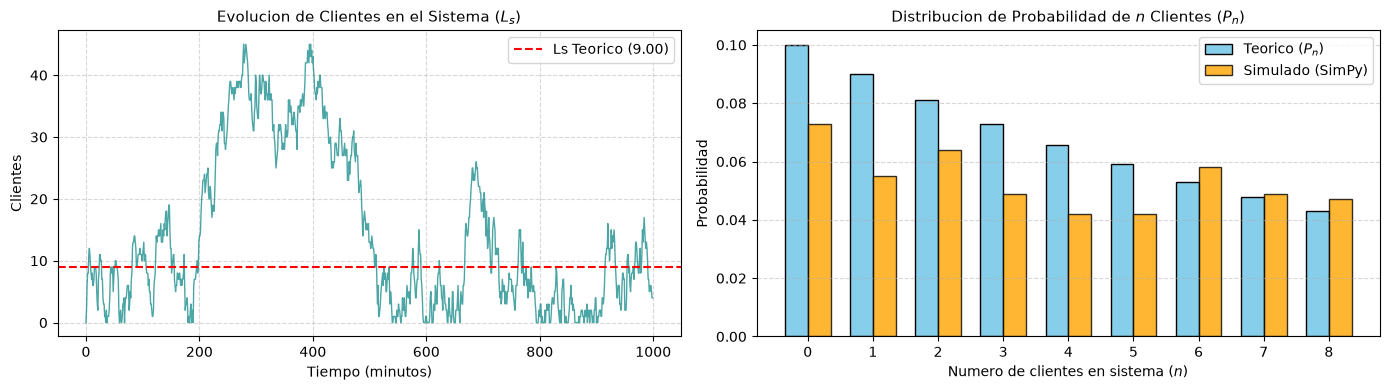

In [50]:
# graficas
fig, axs = plt.subplots(1, 2, figsize=(14, 4))

# evolucion temporal del numero de clientes en el sistema
axs[0].plot(tiempos_registro, tamano_sistema, color='teal', alpha=0.7, linewidth=1)
axs[0].axhline(y=Ls_teorico, color='red', linestyle='--', label=f'Ls Teorico ({Ls_teorico:.2f})')
axs[0].set_title('Evolucion de Clientes en el Sistema ($L_s$)', fontsize=11)
axs[0].set_xlabel('Tiempo (minutos)')
axs[0].set_ylabel('Clientes')
axs[0].legend()
axs[0].grid(True, linestyle='--', alpha=0.5)

# distribucion Pn (Teorica vs Simulada para n de 0 a 8)
n_vals = np.arange(0, 9)
pn_teoricos = [(1 - (LAMBDA / MU)) * ((LAMBDA / MU) ** n) for n in n_vals]
pn_simulados = [np.mean([1 if s == n else 0 for s in tamano_sistema]) for n in n_vals]

width = 0.35
axs[1].bar(n_vals - width/2, pn_teoricos, width, label='Teorico ($P_n$)', color='skyblue', edgecolor='black')
axs[1].bar(n_vals + width/2, pn_simulados, width, label='Simulado (SimPy)', color='orange', edgecolor='black', alpha=0.8)
axs[1].set_title('Distribucion de Probabilidad de $n$ Clientes ($P_n$)', fontsize=11)
axs[1].set_xlabel('Numero de clientes en sistema ($n$)')
axs[1].set_ylabel('Probabilidad')
axs[1].set_xticks(n_vals)
axs[1].legend()
axs[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()